In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


# IMPORTANDO AS BIBLIOTECAS

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

# **1. CARREGAMENTO DOS DADOS**

In [3]:
# CARREGANDO OS DADOS DENTRO DA VARIAVEL df
df = pd.read_csv('/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv')

# **2. Visão geral dos dados**

In [4]:
# VERIFICANDO AS 5 PRIMEIRAS LINHAS DO DATASET
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# Contagem por classe: 0 = normal (284.315), 1 = fraude (492)
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [6]:
# Proporção de fraudes no dataset (prior de fraude): ~0,17%
df['Class'].mean()

np.float64(0.001727485630620034)

In [7]:
# Filtra o dataset mantendo apenas as linhas onde o valor é igual a 1
dataset_filtrado = df[df['Amount'] == 1]

# Mostra as primeiras linhas do dataset filtrado
print(dataset_filtrado.head())

# Conta a quantidade de linhas resultantes do filtro
quantidade_linhas = len(dataset_filtrado)
print(f"Total de linhas encontradas: {quantidade_linhas}")


      Time        V1        V2        V3        V4        V5        V6  \
108   73.0  1.162281  1.248178 -1.581317  1.475024  1.138357 -1.020373   
109   73.0  1.239048  0.293284  0.086472  1.178277  0.373344  0.325596   
166  105.0  1.175094  0.408263  0.552145  1.255068 -0.196662 -0.565605   
168  107.0  1.175125  0.661341 -0.477476  1.102542  0.543328 -0.246785   
245  167.0  1.321778  0.658048 -0.793312  0.429647  0.417966 -0.927679   

           V7        V8        V9  ...       V21       V22       V23  \
108  0.638387 -0.136762 -0.805505  ... -0.124012 -0.227150 -0.199185   
109  0.119319 -0.025476  0.173211  ... -0.148136 -0.111893 -0.173207   
166  0.133973 -0.146202 -0.214155  ...  0.130585  0.523640 -0.050125   
168  0.165234  0.027018 -0.423144  ... -0.003071  0.093738 -0.154355   
245  0.180923 -0.236763  0.020143  ... -0.248709 -0.599280 -0.138226   

          V24       V25       V26       V27       V28  Amount  Class  
108 -0.289757  0.776244 -0.283950  0.056747  0.0847

In [8]:
# Resumo do DataFrame: número de linhas e colunas, tipo de cada coluna e quantidade de valores nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

# **3. Análise exploratória: fraude × transações normais**

#### Quatro gráficos comparando transações normais e fraudes: quantidade por classe, distribuição dos valores (densidade), distribuição acumulada dos valores e transações ao longo do tempo.

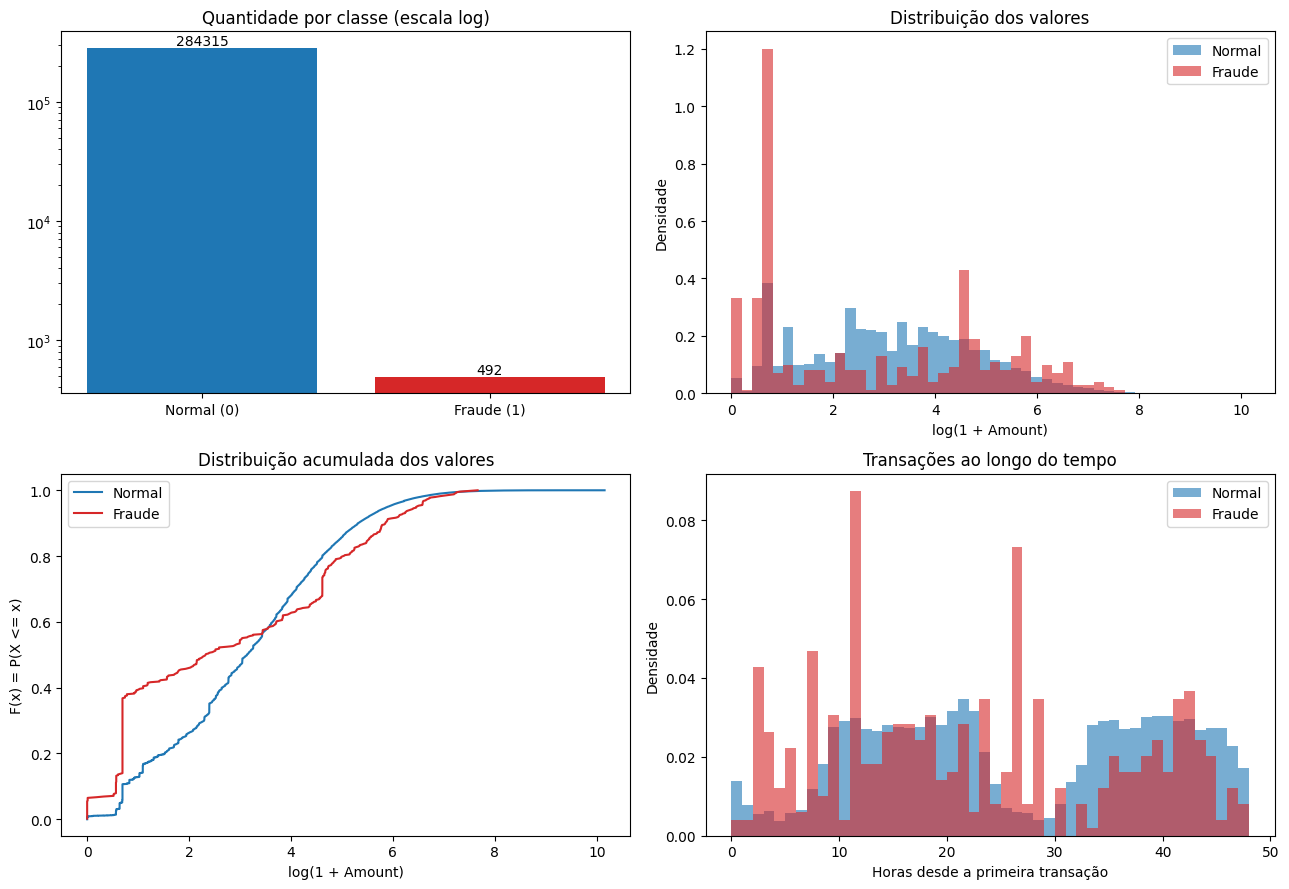

In [9]:
# Separa as transações por classe e gera os 4 gráficos da análise exploratória
normal = df[df['Class'] == 0]
fraude = df[df['Class'] == 1]

# Faixas definidas uma única vez, para normal e fraude usarem exatamente as mesmas
bins_valor = np.histogram_bin_edges(np.log1p(df["Amount"]), bins=50)
bins_tempo = np.histogram_bin_edges(df["Time"] / 3600, bins=48)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Balanceamento das classes (escala log, senão a barra da fraude some)
contagem = df["Class"].value_counts().sort_index()
barras = axes[0, 0].bar(["Normal (0)", "Fraude (1)"], contagem.values,
                        color=["tab:blue", "tab:red"])
axes[0, 0].set_yscale("log")
axes[0, 0].bar_label(barras)
axes[0, 0].set_title("Quantidade por classe (escala log)")

# 2) Histograma dos valores (Amount), normalizado para virar densidade
axes[0, 1].hist(np.log1p(normal["Amount"]), bins=bins_valor, density=True,
                alpha=0.6, label="Normal")
axes[0, 1].hist(np.log1p(fraude["Amount"]), bins=bins_valor, density=True,
                alpha=0.6, label="Fraude", color="tab:red")
axes[0, 1].set_xlabel("log(1 + Amount)")
axes[0, 1].set_ylabel("Densidade")
axes[0, 1].set_title("Distribuição dos valores")
axes[0, 1].legend()

# 3) Distribuição acumulada empírica (F(x) calculada nos dados)
for dados, nome, cor in [(normal, "Normal", "tab:blue"),
                         (fraude, "Fraude", "tab:red")]:
    x = np.sort(dados["Amount"].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1, 0].plot(np.log1p(x), y, label=nome, color=cor)
axes[1, 0].set_xlabel("log(1 + Amount)")
axes[1, 0].set_ylabel("F(x) = P(X <= x)")
axes[1, 0].set_title("Distribuição acumulada dos valores")
axes[1, 0].legend()

# 4) Transações ao longo do tempo (Tempo está em segundos)
axes[1, 1].hist(normal["Time"] / 3600, bins=bins_tempo, density=True,
                alpha=0.6, label="Normal")
axes[1, 1].hist(fraude["Time"] / 3600, bins=bins_tempo, density=True,
                alpha=0.6, label="Fraude", color="tab:red")
axes[1, 1].set_xlabel("Horas desde a primeira transação")
axes[1, 1].set_ylabel("Densidade")
axes[1, 1].set_title("Transações ao longo do tempo")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("visualizacao.png", dpi=150)
plt.show()

# **4. Valores mais frequentes nas fraudes**

In [10]:
# Valores (Amount) das transações fraudulentas
valores_fraude = df[df["Class"] == 1]["Amount"]

# Os 5 valores que mais se repetem entre as fraudes
valores_fraude.value_counts().head(5)

# Proporção das fraudes com valor exatamente igual a 1
(valores_fraude == 1).mean()

# Proporção das fraudes com valor igual a 0
(valores_fraude == 0).mean()

np.float64(0.054878048780487805)

# **5. Probabilidade de fraude por faixa de valor (Bayes)**

#### Para cada faixa de valor da transação, calculei a densidade das fraudes e das transações normais, a razão entre as duas e a probabilidade de fraude dado o valor (posteriori), usando probabilidade total e o teorema de Bayes.

In [11]:
# Valor da transação em escala log, para as faixas não ficarem dominadas por valores altos
df["x"] = np.log1p(df["Amount"])

# Faixas definidas uma única vez, iguais para fraude e normal
bins = np.histogram_bin_edges(df["x"], bins=50)

# Densidade de cada classe em cada faixa: P(valor | classe)
f_fraude, _ = np.histogram(df.loc[df.Class == 1, "x"], bins=bins, density=True)
f_normal, _ = np.histogram(df.loc[df.Class == 0, "x"], bins=bins, density=True)

# Priori: proporção de fraude no dataset
prior = df["Class"].mean()                      # P(fraude) ≈ 0,0017

num = f_fraude * prior                          # P(valor | fraude) * P(fraude)
den = num + f_normal * (1 - prior)              # probabilidade total P(valor)

# Posteriori (Bayes): P(fraude | valor na faixa)
post = np.divide(num, den, out=np.zeros_like(num), where=den > 0)

# Razão de verossimilhança: quantas vezes a faixa é mais típica de fraude do que de normal
with np.errstate(divide="ignore", invalid="ignore"):
    razao = f_fraude / f_normal

# Tabela resumo por faixa
tabela = pd.DataFrame({
    "x_ini": bins[:-1],
    "x_fim": bins[1:],
    "dens_fraude": f_fraude,
    "dens_normal": f_normal,
    "razao": razao,
    "posteriori": post,
})

# As 10 faixas com maior probabilidade de fraude
print(tabela.sort_values("posteriori", ascending=False).head(10))

       x_ini     x_fim  dens_fraude  dens_normal     razao  posteriori
0   0.000000  0.203079     0.330281     0.052928  6.240153    0.010683
32  6.498522  6.701601     0.110094     0.029027  3.792742    0.006520
35  7.107759  7.310838     0.040034     0.011448  3.496980    0.006015
2   0.406158  0.609236     0.330281     0.095257  3.467256    0.005964
3   0.609236  0.812315     1.201023     0.384701  3.121967    0.005373
28  5.686207  5.889286     0.200171     0.075790  2.641115    0.004550
36  7.310838  7.513916     0.020017     0.008660  2.311504    0.003984
22  4.467734  4.670813     0.430367     0.189960  2.265561    0.003905
30  6.092365  6.295444     0.100085     0.050123  1.996807    0.003444
31  6.295444  6.498522     0.070060     0.037150  1.885842    0.003253


# **6. Modelo probabilístico com o valor da transação (treino e teste)**

#### Separei os dados em treino (70%) e teste (30%). As densidades e o priori foram estimados só no treino, e o score de cada transação do teste é a probabilidade de fraude (posteriori) da faixa de valor em que ela cai. Avaliei com PR-AUC e ROC-AUC.

In [12]:
# Separa treino (70%) e teste (30%), mantendo a mesma proporção de fraude nos dois
treino, teste = train_test_split(
    df, test_size=0.3, stratify=df["Class"], random_state=42
)

# Faixas e densidades estimadas só com o treino
bins = np.histogram_bin_edges(treino["x"], bins=50)
f_fraude, _ = np.histogram(treino.loc[treino.Class == 1, "x"], bins=bins, density=True)
f_normal, _ = np.histogram(treino.loc[treino.Class == 0, "x"], bins=bins, density=True)
prior = treino["Class"].mean()

# Bayes: posteriori por faixa (faixas sem dados ficam com o priori)
num = f_fraude * prior
den = num + f_normal * (1 - prior)
post = np.divide(num, den, out=np.full_like(num, prior), where=den > 0)

# Score de cada transação do teste = posteriori da faixa em que o valor dela cai
idx = np.clip(np.digitize(teste["x"], bins) - 1, 0, len(post) - 1)
score = post[idx]

# Avaliação no teste
print("PR-AUC:", average_precision_score(teste["Class"], score))
print("ROC-AUC:", roc_auc_score(teste["Class"], score))
print("PR-AUC de um chute (prior):", teste["Class"].mean())

PR-AUC: 0.004603553414504152
ROC-AUC: 0.7454270393847744
PR-AUC de um chute (prior): 0.0017321489179921118


# **7. Curvas Precisão × Recall e ROC (modelo com o valor da transação)**

#### Curvas de avaliação do modelo que usa só o valor da transação. À esquerda, precisão contra recall (PR-AUC); à direita, a curva ROC (ROC-AUC). A linha tracejada em cada gráfico é o desempenho de um chute.

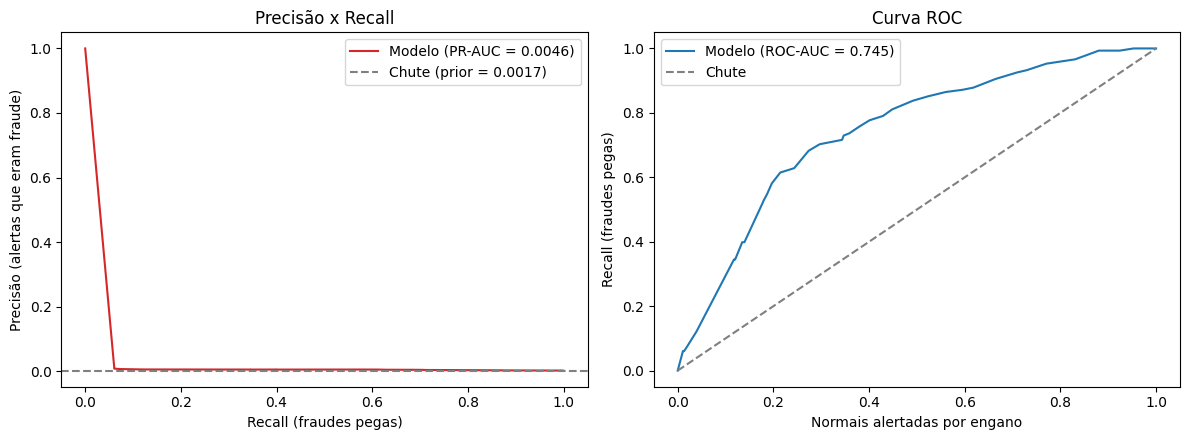

In [13]:
# Extrai as classes reais do conjunto de teste e calcula os pontos das curvas Precision-Recall e ROC.
y = teste["Class"]
prec, rec, _ = precision_recall_curve(y, score)
fpr, tpr, _ = roc_curve(y, score)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Curva precisão x recall (PR-AUC)
ax[0].plot(rec, prec, color="tab:red",
           label=f"Modelo (PR-AUC = {average_precision_score(y, score):.4f})")
ax[0].axhline(y.mean(), color="gray", linestyle="--",
              label=f"Chute (prior = {y.mean():.4f})")
ax[0].set_xlabel("Recall (fraudes pegas)")
ax[0].set_ylabel("Precisão (alertas que eram fraude)")
ax[0].set_title("Precisão x Recall")
ax[0].legend()

# Curva ROC (ROC-AUC)
ax[1].plot(fpr, tpr, color="tab:blue",
           label=f"Modelo (ROC-AUC = {roc_auc_score(y, score):.3f})")
ax[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chute")
ax[1].set_xlabel("Normais alertadas por engano")
ax[1].set_ylabel("Recall (fraudes pegas)")
ax[1].set_title("Curva ROC")
ax[1].legend()

plt.tight_layout()
plt.show()

# **8. Naive Bayes com todas as variáveis**

#### Naive Bayes treinado com todas as variáveis (V1 a V28 e o log do valor da transação), mantendo fora Classe, Quantia e Tempo. Avaliado no conjunto de teste com PR-AUC e ROC-AUC.

In [14]:
# Variáveis usadas no modelo: todas, menos a classe, o valor original e o tempo
colunas_fora = ['Class', 'Amount', 'Time']
X_cols = [c for c in treino.columns if c not in colunas_fora]

# Treina o Naive Bayes (assume que cada variável segue uma normal dentro de cada classe)
nb = GaussianNB()
nb.fit(treino[X_cols], treino["Class"])

# Score = probabilidade de fraude estimada para cada transação do teste
score_nb = nb.predict_proba(teste[X_cols])[:, 1]

# Avaliação no teste
y = teste["Class"]
print("PR-AUC NB:", average_precision_score(y, score_nb))
print("ROC-AUC NB:", roc_auc_score(y, score_nb))
print("PR-AUC do chute:", y.mean())

PR-AUC NB: 0.08099096549950999
ROC-AUC NB: 0.9562822905559877
PR-AUC do chute: 0.0017321489179921118


# **9. Regressão Logística e Random Forest**

#### Treinei a Regressão Logística e o Random Forest com as mesmas variáveis do Naive Bayes, usando class_weight="balanced" para compensar o desbalanceamento (0,17% de fraudes). Comparei os três modelos no mesmo conjunto de teste com PR-AUC e ROC-AUC.

In [15]:
# Classes reais de treino e de teste
y_treino = treino["Class"]
y_teste = teste["Class"]

# Modelos comparados; class_weight="balanced" dá mais peso às fraudes no treino
modelos = {
    "Regressão Logística": make_pipeline(
        StandardScaler(),   # coloca as variáveis na mesma escala (a regressão logística precisa)
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42
    ),
}

# Treina cada modelo, calcula o score no teste e avalia
for nome, modelo in modelos.items():
    modelo.fit(treino[X_cols], y_treino)
    s = modelo.predict_proba(teste[X_cols])[:, 1]
    print(nome)
    print("  PR-AUC:", average_precision_score(y_teste, s))
    print("  ROC-AUC:", roc_auc_score(y_teste, s))

Regressão Logística
  PR-AUC: 0.6977969173926496
  ROC-AUC: 0.9691558549580708
Random Forest
  PR-AUC: 0.8178942493824175
  ROC-AUC: 0.9366905477492266


In [16]:
#1. O valor sozinho dá um sinal fraco.
#2. O Naive Bayes, que é Bayes puro, mostra que somar evidências ajuda muito.
#3. Modelos sem suposição de independência chegam a um nível que já seria útil na prática.

# **10. Recall dos modelos com precisão mínima fixa**

Para comparar a Regressão Logística e o Random Forest de forma justa, fixei a precisão mínima dos alertas (50%, 80% e 90%) e medi quantas fraudes cada modelo consegue pegar (recall) em cada nível.

In [17]:
# Guarda o score (probabilidade de fraude no teste) de cada modelo
scores = {}
for nome, modelo in modelos.items():
    modelo.fit(treino[X_cols], y_treino)
    scores[nome] = modelo.predict_proba(teste[X_cols])[:, 1]

# Para cada modelo, o maior recall possível mantendo a precisão acima de cada alvo
for nome, s in scores.items():
    prec, rec, _ = precision_recall_curve(y_teste, s)
    for alvo in [0.5, 0.8, 0.9]:
        # Se o modelo nunca chega à precisão alvo, sobra só o ponto artificial
        # da curva (recall = 0), e o resultado aparece como 0,00
        recall_no_alvo = rec[prec >= alvo].max()
        print(f"{nome}: com precisão >= {alvo:.0%}, recall = {recall_no_alvo:.2f}")

Regressão Logística: com precisão >= 50%, recall = 0.83
Regressão Logística: com precisão >= 80%, recall = 0.78
Regressão Logística: com precisão >= 90%, recall = 0.00
Random Forest: com precisão >= 50%, recall = 0.84
Random Forest: com precisão >= 80%, recall = 0.82
Random Forest: com precisão >= 90%, recall = 0.79


# **11. Alertas do Random Forest por limite de decisão**

#### Para o Random Forest, testei três limites de alerta (0,3, 0,5 e 0,7). Em cada um, contei quantos alertas o modelo deu, quantos eram fraude de verdade, quantos eram falsos e quantas fraudes passaram sem alerta, junto com a precisão e o recall.

In [18]:
# Score (probabilidade de fraude no teste) do Random Forest
s = scores["Random Forest"]

for limite in [0.3, 0.5, 0.7]:
    # Transação com score acima do limite gera alerta (1); abaixo, não (0)
    previsto = (s >= limite).astype(int)

    # Contagens: vn = normais sem alerta, fp = alertas falsos,
    # fn = fraudes que passaram, vp = fraudes pegas
    vn, fp, fn, vp = confusion_matrix(y_teste, previsto).ravel()

    print(f"Limite {limite}")
    print("  alertas dados:", vp + fp)
    print("  alertas que eram fraude (vp):", vp)
    print("  alertas falsos (fp):", fp)
    print("  fraudes que passaram (fn):", fn)
    # Precisão = vp / alertas dados | Recall = vp / fraudes reais
    print("  precisão:", round(vp / (vp + fp), 2), "| recall:", round(vp / (vp + fn), 2))

Limite 0.3
  alertas dados: 124
  alertas que eram fraude (vp): 115
  alertas falsos (fp): 9
  fraudes que passaram (fn): 33
  precisão: 0.93 | recall: 0.78
Limite 0.5
  alertas dados: 108
  alertas que eram fraude (vp): 105
  alertas falsos (fp): 3
  fraudes que passaram (fn): 43
  precisão: 0.97 | recall: 0.71
Limite 0.7
  alertas dados: 95
  alertas que eram fraude (vp): 93
  alertas falsos (fp): 2
  fraudes que passaram (fn): 55
  precisão: 0.98 | recall: 0.63


# **12. Validação cruzada dos modelos**

#### Para confirmar que a diferença entre os modelos não foi sorte de uma única divisão dos dados, fiz validação cruzada estratificada com 5 divisões no conjunto de treino, usando o PR-AUC como nota.

In [19]:
# Define 5 divisões do treino, cada uma mantendo a proporção de fraude
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nome, modelo in modelos.items():
    # Em cada rodada, treina com 4 partes e testa na parte restante; devolve o PR-AUC de cada rodada
    notas = cross_val_score(
        modelo, treino[X_cols], y_treino,
        cv=cv, scoring="average_precision", n_jobs=-1
    )
    print(nome)
    print("  PR-AUC em cada divisão:", notas.round(3))
    print("  média:", notas.mean().round(3))

Regressão Logística
  PR-AUC em cada divisão: [0.832 0.733 0.775 0.821 0.714]
  média: 0.775
Random Forest
  PR-AUC em cada divisão: [0.87  0.853 0.88  0.849 0.825]
  média: 0.855


# **13. Variáveis mais importantes do Random Forest**

#### Ranking das 10 variáveis que mais contribuem para as decisões do Random Forest. Cada valor é a parcela da decisão do modelo que vem daquela variável, e a soma de todas as variáveis dá 1.

In [20]:
# Random Forest já treinado no conjunto de treino
rf = modelos["Random Forest"]

# Importância de cada variável, ligada ao nome da coluna
importancia = pd.Series(rf.feature_importances_, index=X_cols)

# As 10 variáveis mais importantes
print(importancia.sort_values(ascending=False).head(10).round(3))

V10    0.158
V14    0.156
V4     0.116
V12    0.104
V17    0.092
V11    0.070
V3     0.043
V7     0.040
V16    0.033
V9     0.020
dtype: float64


# **14. Distribuição das 10 variáveis mais importantes, por classe**

#### Para cada uma das 10 variáveis mais importantes do Random Forest, comparei a densidade das transações normais (azul) e das fraudes (vermelho). Quanto mais separadas as duas cores, mais a variável ajuda o modelo a distinguir fraude de transação normal. Os valores extremos foram agrupados nas bordas do gráfico para o eixo não ficar esticado.

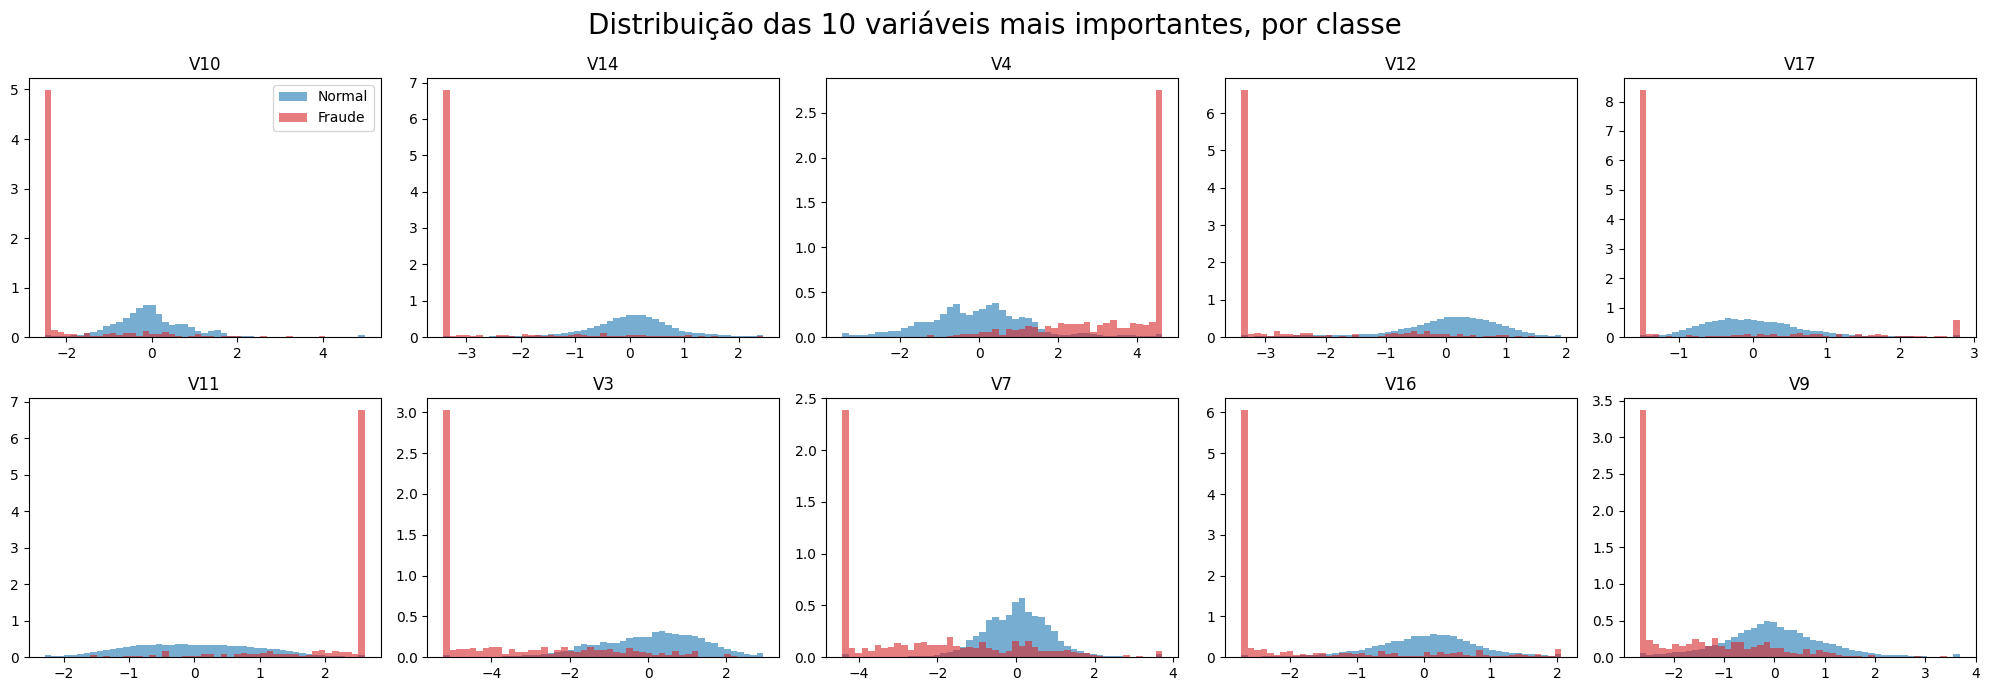

In [21]:
# Nomes das 10 variáveis mais importantes
top = importancia.sort_values(ascending=False).head(10).index

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
fig.suptitle("Distribuição das 10 variáveis mais importantes, por classe", fontsize=20)

for ax, col in zip(axes.ravel(), top):
    # Limites do eixo: ignora os 0,5% mais extremos de cada lado
    baixo, alto = np.percentile(df[col], [0.5, 99.5])
    bins_col = np.linspace(baixo, alto, 50)          # mesmas faixas para as duas cores

    # Valores além dos limites são empurrados para a borda (por isso as barras das pontas ficam altas)
    normal_col = np.clip(df.loc[df.Class == 0, col], baixo, alto)
    fraude_col = np.clip(df.loc[df.Class == 1, col], baixo, alto)

    ax.hist(normal_col, bins=bins_col, density=True, alpha=0.6, color="tab:blue", label="Normal")
    ax.hist(fraude_col, bins=bins_col, density=True, alpha=0.6, color="tab:red", label="Fraude")
    ax.set_title(col)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

# Como ler:
# Vermelho e azul separados: a variável distingue bem fraude de normal, e é por isso que ela pesa no modelo.
# Vermelho e azul sobrepostos: a variável ajuda pouco.